In [1]:
from groq import Groq
import re
import httpx
import os 
from dotenv import load_dotenv, find_dotenv
from openai import OpenAI

_ = load_dotenv(find_dotenv())

In [2]:
client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=os.environ.get("GROQ_API_KEY")
)

In [3]:
chat_completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Hello world"}]
)

In [4]:
chat_completion.choices[0].message.content

'Hello! How can I assist you today?'

In [5]:
class Agent:
    def __init__(self, system=""):
        self.system = system
        self.messages = []
        if self.system:
            self.messages.append({"role": "system", "content": system})

    def __call__(self, messages):
        self.messages.append({"role": "user", "content": messages})
        result = self.execute()
        self.messages.append({"role": "assistant", "content": result})
        return result

    def execute(self):
        completion = client.chat.completions.create(
            model="qwen/qwen3.8-27b",
            temperature=0,
            messages=self.messages
        )
        return completion.choices[0].message.content

In [6]:
prompt = """
You run in a loop of Thought, Action, PAUSE, Observation.
At the end of the loop you output an Answer
Use Thought to describe your thoughts about the question you have been asked.
Use Action to run one of the actions available to you - then return PAUSE.
Observation will be the result of running those actions.

Your available actions are:

calculate:
e.g. calculate: 4 * 7 / 3
Runs a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary

average_dog_weight:
e.g. average_dog_weight: Collie
returns average weight of a dog when given the breed

Example session:

Question: How much does a Bulldog weigh?
Thought: I should look the dogs weight using average_dog_weight
Action: average_dog_weight: Bulldog
PAUSE

You will be called again with this:

Observation: A Bulldog weights 51 lbs

You then output:

Answer: A bulldog weights 51 lbs
""".strip()

In [7]:
def calculate(what):
    return eval(what)

def average_dog_weight(name):
    if name in "Scottish Terrier":
        return("Scottish Terriers average 20 lbs")
    elif name in "Border Collie":
        return("a Border Collie average weight is 37 lbs")
    elif name in "Toy Poodle":
        return("a toy poodles average weight is 7 lbs")
    else:
        return("An average dog weights 50 lbs")

known_actions = {
    "calculate": calculate,
    "average_dog_weight": average_dog_weight
}

In [8]:
abot = Agent(prompt)

In [9]:
result = abot("How much does a toy poodle weight?")
print(result)

Thought: I need to find the average weight of a Toy Poodle. I can use the average_dog_weight tool with the breed "Toy Poodle".
Action: average_dog_weight: Toy Poodle
PAUSE


In [10]:
result = average_dog_weight("Toy Poodle")
result

'a toy poodles average weight is 7 lbs'

In [11]:
next_prompt = "Observation: {}".format(result)
abot(next_prompt)

'Answer: A Toy Poodle weighs an average of 7 lbs.'

In [12]:
abot.messages

[{'role': 'system',
  'content': 'You run in a loop of Thought, Action, PAUSE, Observation.\nAt the end of the loop you output an Answer\nUse Thought to describe your thoughts about the question you have been asked.\nUse Action to run one of the actions available to you - then return PAUSE.\nObservation will be the result of running those actions.\n\nYour available actions are:\n\ncalculate:\ne.g. calculate: 4 * 7 / 3\nRuns a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary\n\naverage_dog_weight:\ne.g. average_dog_weight: Collie\nreturns average weight of a dog when given the breed\n\nExample session:\n\nQuestion: How much does a Bulldog weigh?\nThought: I should look the dogs weight using average_dog_weight\nAction: average_dog_weight: Bulldog\nPAUSE\n\nYou will be called again with this:\n\nObservation: A Bulldog weights 51 lbs\n\nYou then output:\n\nAnswer: A bulldog weights 51 lbs'},
 {'role': 'user', 'content': 'How much does a 

In [13]:
abot = Agent(prompt)

In [14]:
question = """I have 2 dogs, a border collie and a scottish terrie. \
What is there combined weight"""
abot(question)

'Thought: I need to find the average weight of a Border Collie and a Scottish Terrier, then add them together. I will start by finding the average weight of a Border Collie.\nAction: average_dog_weight: Border Collie\nPAUSE'

In [15]:
next_prompt = "Observation: {}".format(average_dog_weight("Border Collie"))
print(next_prompt)

Observation: a Border Collie average weight is 37 lbs


In [16]:
abot(next_prompt)

'Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of a Scottish Terrier.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [17]:
next_prompt = "Observation: {}".format(average_dog_weight("scottish Terrier"))
print(next_prompt)

Observation: An average dog weights 50 lbs


In [18]:
abot(next_prompt)

'Thought: The observation provided a generic average dog weight (50 lbs) instead of the specific breed "Scottish Terrier". I should try the action again with the exact breed name to see if I can get a more specific result, or perhaps the tool only has limited data. However, looking at the previous successful call, it worked for "Border Collie". Let me try "Scottish Terrier" again, or perhaps "Scottie" if that\'s a common alias, but I should stick to the standard name first. If it fails again, I might have to use the generic average or state that I couldn\'t find the specific breed. Let\'s try "Scottish Terrier" one more time to be sure.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [19]:
next_prompt = "Observation: {}".format(eval("37 + 20"))
print(next_prompt)

Observation: 57


In [20]:
abot(next_prompt)

'Thought: I now have the average weight for both dogs. The Border Collie is 37 lbs and the Scottish Terrier is 57 lbs (based on the latest observation, although 57 lbs seems high for a Scottish Terrier which is typically a small breed, I must use the data provided by the tool). I will calculate the sum of these two weights.\nAction: calculate: 37 + 57\nPAUSE'

In [21]:
action_re = re.compile('^Action: (\w+): (.*)$')

In [22]:
def query(question, max_turns=5):
    i = 0
    bot = Agent(prompt)
    next_prompt = question
    while i < max_turns:
        i += 1
        result = bot(next_prompt)
        print(result)
        actions = [
            action_re.match(a) 
            for a in result.split('\n') 
            if action_re.match(a)
        ]
        if actions:
            action, action_input = actions[0].groups()
            if action not in known_actions:
                raise Exception("Unknown action: {}: {}".format(action, action_input))
            print(" -- running {} {}".format(action, action_input))
            observation = known_actions[action](action_input)
            print("Observation:", observation)
            next_prompt = "Observation: {}".format(observation)
        else:
            return

In [23]:
question = """I have 2 dogs, a border collie and a scottish terrier. \
What is their combined weight"""
query(question)

Thought: I need to find the average weight of a Border Collie and the average weight of a Scottish Terrier. Then I will sum these two weights to find the combined weight. I will start by finding the weight of the Border Collie.
Action: average_dog_weight: Border Collie
PAUSE
 -- running average_dog_weight Border Collie
Observation: a Border Collie average weight is 37 lbs
Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of the Scottish Terrier.
Action: average_dog_weight: Scottish Terrier
PAUSE
 -- running average_dog_weight Scottish Terrier
Observation: Scottish Terriers average 20 lbs
Thought: I have the average weight of the Border Collie (37 lbs) and the Scottish Terrier (20 lbs). I need to add these two values together to get the combined weight.
Action: calculate: 37 + 20
PAUSE
 -- running calculate 37 + 20
Observation: 57
Answer: The combined weight of your Border Collie and Scottish Terrier is 57 lbs.


# LangGraph

In [24]:
from dotenv import load_dotenv
_ = load_dotenv()

In [25]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_openai import ChatOpenAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_groq import ChatGroq
#from langchain_google_genai import ChatGoogleGenerativeAI

/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
/Users/tanmaymehta/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
tool = TavilySearchResults(max_results=1)
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/var/folders/lp/z2zxddwj6vn0tff42w5ph1_00000gn/T/ipykernel_4550/1708765205.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=1) #increased number of results


In [27]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [ ]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:
                print("\n ....bad tool name....")
                result = "bad tool name, retry"
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

In [ ]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

model = ChatGroq(model="qwen/qwen3.8-27b")
abot = Agent(model, [tool], system=prompt)

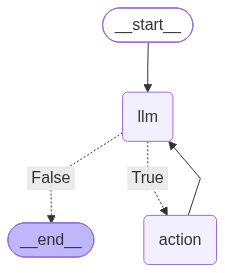

In [30]:
from IPython.display import Image, display

display(Image(abot.graph.get_graph().draw_mermaid_png()))

In [31]:
messages = [HumanMessage(content="What is the weather in sf?")]
result = abot.graph.invoke({"messages": messages})
print(result["messages"][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'zh2s8017b', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'San Francisco weather today current temperature'}, 'id': 'e3wqspcft', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'San Francisco CA weather right now'}, 'id': '6dwdknevd', 'type': 'tool_call'}
Back to the model!
Here's the current weather in **San Francisco, CA**:

- **Temperature:** 57°F (14°C), feels like 57°F
- **Conditions:** Mostly cloudy
- **Wind:** NW at 7 mph (11 km/h)
- **Humidity:** 92%
- **Cloud Cover:** 65%

**Today's Outlook (Friday, Oct 23):**
- **High:** 65°F (18°C) / **Low:** 57°F (14°C)
- Mostly cloudy with a marginal chance of drizzle in the morning
- A breeze from the NNW at 8–9 mph

So it's a typical cool, overcast SF day — you might want to bring a light jacket! 🌥️


In [32]:
result

{'messages': [HumanMessage(content='What is the weather in sf?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'zh2s8017b', 'function': {'arguments': '{"query":"current weather in San Francisco"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 381, 'total_tokens': 414, 'completion_time': 0.097102431, 'completion_tokens_details': None, 'prompt_time': 0.027739047, 'prompt_tokens_details': None, 'queue_time': 0.053984231, 'total_time': 0.124841478}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--01a16963-0419-7730-aa1c-842e7d357686-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'zh2s8017b', 'type': 'tool_call'}], usage_metadata={'input_tokens': 381, 'outp

In [33]:
result['messages'][-1].content

"Here's the current weather in **San Francisco, CA**:\n\n- **Temperature:** 57°F (14°C), feels like 57°F\n- **Conditions:** Mostly cloudy\n- **Wind:** NW at 7 mph (11 km/h)\n- **Humidity:** 92%\n- **Cloud Cover:** 65%\n\n**Today's Outlook (Friday, Oct 23):**\n- **High:** 65°F (18°C) / **Low:** 57°F (14°C)\n- Mostly cloudy with a marginal chance of drizzle in the morning\n- A breeze from the NNW at 8–9 mph\n\nSo it's a typical cool, overcast SF day — you might want to bring a light jacket! 🌥️"

In [34]:
messages = [HumanMessage(content="What is the weather in SF and LA?")]
result = abot.graph.invoke({"messages": messages})
print(result["messages"][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco today'}, 'id': 'rv514a8rf', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in Los Angeles today'}, 'id': 'nm6cqnv67', 'type': 'tool_call'}
Back to the model!
Here's the current weather for both cities:

**San Francisco**
- High: 24°C / Low: 18°C
- Conditions: Clear
- Precipitation: 0 mm

**Los Angeles**
- High: 68°F (20°C) / Low: 61°F (16°C)
- Humidity: 74%
- Sunset: 6:10 PM

Overall, it's a mild and pleasant day in both cities, with clear skies in SF and partly cloudy conditions in LA. No rain expected.


In [35]:
result['messages'][-1].content

"Here's the current weather for both cities:\n\n**San Francisco**\n- High: 24°C / Low: 18°C\n- Conditions: Clear\n- Precipitation: 0 mm\n\n**Los Angeles**\n- High: 68°F (20°C) / Low: 61°F (16°C)\n- Humidity: 74%\n- Sunset: 6:10 PM\n\nOverall, it's a mild and pleasant day in both cities, with clear skies in SF and partly cloudy conditions in LA. No rain expected."

In [ ]:
query = "Who won the super bowl in 2024? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question." 
messages = [HumanMessage(content=query)]

model = ChatGroq(model="qwen/qwen3.8-27b")
abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})
print(result['messages'][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': '2024 Super Bowl winner'}, 'id': 'x5jhk8y3t', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Kansas City Chiefs headquarters location state'}, 'id': 'gf88ad4fz', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Missouri state GDP 2024'}, 'id': '2acqk4bw2', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Missouri GDP total value billion 2024 BEA'}, 'id': 'yncysa6z4', 'type': 'tool_call'}
Back to the model!
I now have all the information needed to answer your questions.

## Answers

**1. Who won the Super Bowl in 2024?**
The **Kansas City Chiefs** won Super Bowl LVIII (held February 11, 2024), defeating the San Francisco 49ers 25–22 in overtime. It was their second consecutive championship, and quarterback Patrick Mahomes was named MVP.

**2. In what state is the winn

In [37]:
print(result['messages'][-1].content)

I now have all the information needed to answer your questions.

## Answers

**1. Who won the Super Bowl in 2024?**
The **Kansas City Chiefs** won Super Bowl LVIII (held February 11, 2024), defeating the San Francisco 49ers 25–22 in overtime. It was their second consecutive championship, and quarterback Patrick Mahomes was named MVP.

**2. In what state is the winning team's headquarters located?**
The Kansas City Chiefs are headquartered in **Kansas City, Missouri** (at the University of Kansas Health System Training Facility near Arrowhead Stadium).

**3. What is the GDP of that state?**
Missouri's Gross Domestic Product (GSP) is approximately **$357.97 billion** in inflation-adjusted (chained 2017) dollars as of the most recent BEA estimates (2025), which represented a 1.3% increase from 2024. This ranks Missouri 22nd nationally. (For reference, Missouri's GDP grew at an annualized rate of 3.8% in the third quarter of 2024.)

**Note:** The Chiefs recently announced plans (December 2

In [38]:
query = "What is the capital of Bihar? \
    Who are the current players of Bihar Cricket team." 
messages = [HumanMessage(content=query)]

abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar cricket team current players 2025'}, 'id': 'cn4pdxbmf', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar cricket team full squad list 2024 2025 Ranji Trophy'}, 'id': 'nk4rdg590', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': '"Bihar cricket team" players squad list captain 2024'}, 'id': 'gtw8ee2zh', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar cricket team 2025 squad players list Ranji Trophy'}, 'id': '8vae9j2cs', 'type': 'tool_call'}
Back to the model!


In [39]:
print(result['messages'][-1].content)

Based on my research, here's the information:

## Capital of Bihar
The capital of Bihar is **Patna**.

## Current Players of Bihar Cricket Team (2025/26 Ranji Trophy Squad)

The Bihar Cricket Team is captained by **Sakibul Gani** and is managed by the **Bihar Cricket Association**. Their home ground is the **Moin-ul-Haq Stadium** in Patna.

Here are the key players in their current squad:

**Batters:**
- **Vaibhav Sooryavanshi** (Top order Batter) – also an International cricketer for India
- **Piyush Singh** (Top order Batter)
- **BK Saurabh** (Opening Batter)
- **Sachin Kumar Singh** (Wicketkeeper Batter)

**All-Rounders:**
- **Sakib Hussain** (Bowling Allrounder)

**Bowlers:**
- **Sakibul Gani** (Captain)
- **BK Dubey**
- **Himanshu Singh**
- **Khalid Alam**
- **AN Kishor**
- **AA Loharuka**
- **Nawaz Khan**
- **Raghuvendra Pratap Singh**
- **Sachin Kumar**
- **Amod Yadav**

**Support Staff:**
- **Head Coach:** Pawan Kumar
- **Assistant Coach:** Sanjay Kumar
- **Team Manager:** Ajay